In [1]:
!pip install ultralytics roboflow -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 42.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.8/85.8 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 20.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 71.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 120.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 97.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 48.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 13.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/12

In [2]:
from roboflow import Roboflow
from ultralytics import YOLO
import os

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [8]:
from roboflow import Roboflow
rf = Roboflow(api_key=os.environ["ROBOFLOW_API_KEY"])  # set your own key
project = rf.workspace("meva-wfywb").project("fish-fresh-and-non-fresh")
version = project.version(1)
dataset = version.download("folder")

loading Roboflow workspace...
loading Roboflow project...


In [4]:
model = YOLO("yolov8s.pt")

100%|██████████| 21.5M/21.5M [00:00<00:00, 217MB/s]


In [7]:
import os
import cv2

# Base directory of your dataset
base_dir = "/content/FISH-FRESH-AND-NON-FRESH-1"
splits = ["train", "valid", "test"]
classes = ["Fresh Fish", "Non Fresh Fish"]
class_map = {name: idx for idx, name in enumerate(classes)}

# Loop through each dataset split
for split in splits:
    print(f"Processing {split}...")

    for class_name in classes:
        # Input image directory
        img_dir = os.path.join(base_dir, split, class_name)

        # Output label directory
        label_class_dir = os.path.join(base_dir, split, class_name + " Labels")
        os.makedirs(label_class_dir, exist_ok=True)

        for fname in os.listdir(img_dir):
            if fname.lower().endswith(('.jpg', '.jpeg', '.png')):
                img_path = os.path.join(img_dir, fname)
                image = cv2.imread(img_path)
                if image is None:
                    print(f"Skipping unreadable image: {img_path}")
                    continue

                h, w = image.shape[:2]

                # 95% centered bounding box
                box_w = 0.95
                box_h = 0.95
                x_center = 0.5
                y_center = 0.5

                # Prepare YOLO label
                class_id = class_map[class_name]
                yolo_line = f"{class_id} {x_center} {y_center} {box_w} {box_h}\n"

                # Save label to new folder
                label_path = os.path.join(label_class_dir, os.path.splitext(fname)[0] + ".txt")
                with open(label_path, "w") as f:
                    f.write(yolo_line)

print("✅ All labels generated in new folders.")

Processing train...
Processing valid...
Processing test...
✅ All labels generated in new folders.


In [6]:
import os
import shutil

base_dir = "/content/FISH-FRESH-AND-NON-FRESH-1"
splits = ["train", "valid", "test"]
classes = ["Fresh Fish", "Non Fresh Fish"]

for split in splits:
    for class_name in classes:
        # Source: where labels are currently stored
        label_folder = os.path.join(base_dir, split, class_name + " Labels")

        # Target: image folder where labels should go
        image_folder = os.path.join(base_dir, split, class_name)

        if not os.path.exists(label_folder):
            continue

        for fname in os.listdir(label_folder):
            if fname.endswith('.txt'):
                src = os.path.join(label_folder, fname)
                dst = os.path.join(image_folder, fname)
                shutil.copy(src, dst)

print("✅ All label files copied to image folders.")

✅ All label files copied to image folders.


In [9]:
import os

# List all files and folders inside the dataset
dataset_path = dataset.location
for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, '').count(os.sep)
    indent = ' ' * 4 * level
    print(f"{indent}{os.path.basename(root)}/")
    subindent = ' ' * 4 * (level + 1)
    for f in files:
        print(f"{subindent}{f}")

FISH-FRESH-AND-NON-FRESH-1/
    README.dataset.txt
    README.roboflow.txt
    train/
        Non Fresh Fish Labels/
            3873_png.rf.d6a43f43534940efc6f2e1b0a65e82df.txt
            4367_png.rf.4478aefbf1d29066a96f6616e1905683.txt
            879_png.rf.3c201b2ffa34e6bcdf2ccc50ff30b3de.txt
            556_png.rf.632f0b8cda8f841ecbc82130bbe3ba8e.txt
            2075_png.rf.5c70a1fd90868d9de7852ec94abf4f59.txt
            4457_png.rf.e684a5988e8da44869a7c9e8871cec37.txt
            4083_png.rf.a20eb77809338892a4f8697c61fa7eb0.txt
            414_png.rf.6cddd0a85adec5c72c3fcbc49c4ed45e.txt
            1196_png.rf.53923e57bcdc3452599a12ee946ab794.txt
            4036_png.rf.fa75f79b674a302348441e09d59fd3e7.txt
            1028_png.rf.b4641f5612f27c7b5e780847af8a9171.txt
            513_png.rf.27584e12998f4854bb156f3d05c3201b.txt
            335_png.rf.cad9f18099323be79ddc2daeec00988f.txt
            2281_png.rf.d852f3c2ff276c8a04a92d074919f6ba.txt
            671_png.rf.b4e641d8d0b

In [ ]:
model.train(
    data=os.path.join(dataset.location, "/content/FISH-FRESH-AND-NON-FRESH-1/data.yaml"),
    epochs=100,
    imgsz=640,
    batch=16,
    name="fish-freshness-yolov8",
    pretrained=True,
    patience=20,
    verbose=True
)

Ultralytics 8.3.146 🚀 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/FISH-FRESH-AND-NON-FRESH-1/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=fish-freshness-yolov8, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=20, perspective=0.0, 

100%|██████████| 755k/755k [00:00<00:00, 27.8MB/s]

Overriding model.yaml nc=80 with nc=2

                   from  n    params  module                                       arguments                     
  0                  -1  1       928  ultralytics.nn.modules.conv.Conv             [3, 32, 3, 2]                 
  1                  -1  1     18560  ultralytics.nn.modules.conv.Conv             [32, 64, 3, 2]                
  2                  -1  1     29056  ultralytics.nn.modules.block.C2f             [64, 64, 1, True]             
  3                  -1  1     73984  ultralytics.nn.modules.conv.Conv             [64, 128, 3, 2]               
  4                  -1  2    197632  ultralytics.nn.modules.block.C2f             [128, 128, 2, True]           
  5                  -1  1    295424  ultralytics.nn.modules.conv.Conv             [128, 256, 3, 2]              
  6                  -1  2    788480  ultralytics.nn.modules.block.C2f             [256, 256, 2, True]           
  7                  -1  1   1180672  ultralytics

 18                  -1  1    493056  ultralytics.nn.modules.block.C2f             [384, 256, 1]                 
 19                  -1  1    590336  ultralytics.nn.modules.conv.Conv             [256, 256, 3, 2]              
 20             [-1, 9]  1         0  ultralytics.nn.modules.conv.Concat           [1]                           
 21                  -1  1   1969152  ultralytics.nn.modules.block.C2f             [768, 512, 1]                 
 22        [15, 18, 21]  1   2116822  ultralytics.nn.modules.head.Detect           [2, [128, 256, 512]]          
Model summary: 129 layers, 11,136,374 parameters, 11,136,358 gradients, 28.6 GFLOPs

Transferred 349/355 items from pretrained weights
Freezing layer 'model.22.dfl.conv.weight'
AMP: running Automatic Mixed Precision (AMP) checks...


100%|██████████| 5.35M/5.35M [00:00<00:00, 145MB/s]


...

                   all        853        853      0.956      0.951      0.976      0.976

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


     17/100      6.49G      0.142      0.416     0.8975         36        640: 100%|██████████| 187/187 [01:01<00:00,  3.05it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 27/27 [00:08<00:00,  3.06it/s]

                   all        853        853      0.938      0.947      0.972      0.972



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


     18/100      6.53G     0.1422     0.4229     0.9021         36        640: 100%|██████████| 187/187 [01:00<00:00,  3.11it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95):  93%|█████████▎| 25/27 [00:08<00:00,  3.53it/s]

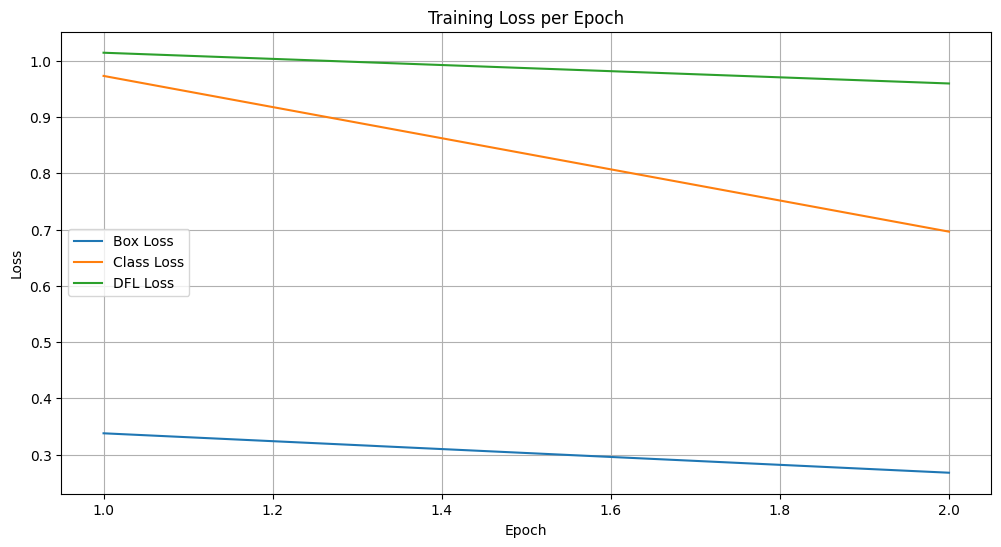

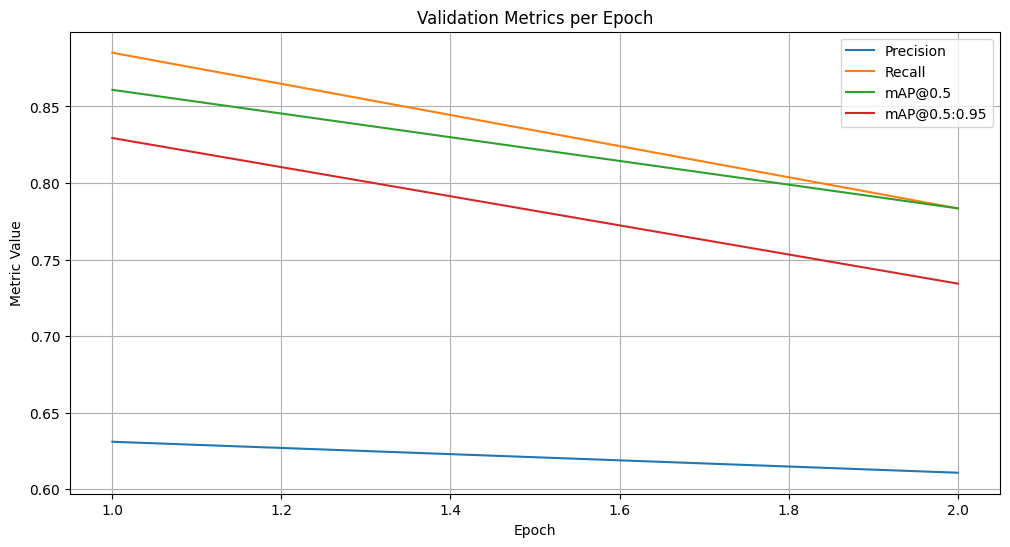

In [ ]:
# prompt: loss curve and acuracy curve

import matplotlib.pyplot as plt
import pandas as pd
import os

# Assuming the results are saved in runs/detect/fish-freshness-yolov8
results_path = "/content/runs/detect/fish-freshness-yolov8/results.csv"

if os.path.exists(results_path):
    results_df = pd.read_csv(results_path)

    # Plotting Training Loss
    plt.figure(figsize=(12, 6))
    plt.plot(results_df['epoch'], results_df['train/box_loss'], label='Box Loss')
    plt.plot(results_df['epoch'], results_df['train/cls_loss'], label='Class Loss')
    plt.plot(results_df['epoch'], results_df['train/dfl_loss'], label='DFL Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Training Loss per Epoch')
    plt.legend()
    plt.grid(True)
    plt.show()

    # Plotting Validation Metrics (including mAP)
    plt.figure(figsize=(12, 6))
    plt.plot(results_df['epoch'], results_df['metrics/precision(B)'], label='Precision')
    plt.plot(results_df['epoch'], results_df['metrics/recall(B)'], label='Recall')
    plt.plot(results_df['epoch'], results_df['metrics/mAP50(B)'], label='mAP@0.5')
    plt.plot(results_df['epoch'], results_df['metrics/mAP50-95(B)'], label='mAP@0.5:0.95')
    plt.xlabel('Epoch')
    plt.ylabel('Metric Value')
    plt.title('Validation Metrics per Epoch')
    plt.legend()
    plt.grid(True)
    plt.show()

else:
    print(f"Results file not found at: {results_path}")
    print("Please check the training output directory.")